# Chapter 14: Observability & LLMOps (notebook)

Everything the chapter measures, in order. Prerequisites (see the README):

```bash
docker compose -f datasets/shopflow/docker-compose.yml up -d
docker compose -p ch14-langfuse --env-file ch14/01_main-chapter-code/langfuse/langfuse.env \
    -f ch14/01_main-chapter-code/langfuse/docker-compose.yml up -d
```

Run headless from `ch14/01_main-chapter-code/`:
`uv run jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=1800 ch14.ipynb`

## 0. Setup and sanity checks

In [1]:
import json, os, subprocess, sys, time
from datetime import UTC, datetime, timedelta
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
import ch14_obs as obs
from llmprod import connect, get_settings

s = get_settings()
IMAGES = Path("../images"); IMAGES.mkdir(exist_ok=True)
RESULTS = Path("eval/results"); RESULTS.mkdir(parents=True, exist_ok=True)
STARTED = datetime.now(UTC)
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)

def openrouter_key_usage() -> float:
    r = httpx.get("https://openrouter.ai/api/v1/key",
                  headers={"Authorization": f"Bearer {s.llm_api_key}"}, timeout=20)
    return r.json()["data"]["usage"]

KEY_USAGE_BEFORE = openrouter_key_usage()
SPEND = []   # every OpenRouter cost this notebook incurs, as reported in usage.cost

with connect() as conn:
    print("orders, payment attempts, successful payments today:", conn.execute("""
        SELECT (SELECT count(*) FROM orders   WHERE placed_at  >= date_trunc('day', now())),
               (SELECT count(*) FROM payments WHERE created_at >= date_trunc('day', now())),
               (SELECT count(*) FROM payments WHERE created_at >= date_trunc('day', now())
                                               AND status = 'succeeded')""").fetchone())
print("models:", s.llm_model, "| judge:", s.llm_model_strong)
print("langfuse:", obs.langfuse_settings()["base_url"])

orders, payment attempts, successful payments today: (100, 102, 98)
models: openai/gpt-6-luna | judge: anthropic/claude-sonnet-5.5
langfuse: http://localhost:3014


## 1. The Langfuse stack: what's running and what it costs in RAM

In [2]:
ps = subprocess.run(["docker", "compose", "-p", "ch14-langfuse", "ps", "--format", "json"],
                    capture_output=True, text=True, check=True).stdout
services = [json.loads(line) for line in ps.splitlines() if line.strip()]
stats = subprocess.run(["docker", "stats", "--no-stream", "--format", "{{json .}}"]
                       + [c["Name"] for c in services], capture_output=True, text=True,
                       check=True).stdout
def mib(text):
    v = text.split("/")[0].strip()
    for unit, f in (("GiB", 1024), ("MiB", 1), ("KiB", 1 / 1024)):
        if v.endswith(unit):
            return float(v[:-len(unit)]) * f
    return float(v.rstrip("B")) / 2**20
mem = {json.loads(l)["Name"]: mib(json.loads(l)["MemUsage"]) for l in stats.splitlines()}
stack = pd.DataFrame([{"service": c["Service"], "image": c["Image"].split("/")[-1],
                       "state": c["State"], "health": c.get("Health") or "-",
                       "mem_MiB": round(mem.get(c["Name"], 0))} for c in services])
print(stack.sort_values("mem_MiB", ascending=False).to_string(index=False))
print(f"\ntotal: {stack.mem_MiB.sum():,.0f} MiB across {len(stack)} containers")
(RESULTS / "stack-memory.json").write_text(stack.to_json(orient="records", indent=1))

            service                       image   state  health  mem_MiB
       langfuse-web             langfuse:4.76.0 running       -      891
    langfuse-worker      langfuse-worker:4.76.0 running       -      714
         clickhouse clickhouse-server:26.3.62.3 running healthy      604
              minio                       minio running healthy      173
           postgres                 postgres:17 running healthy       49
langfuse-ai-gateway           ai-gateway:4.76.0 running healthy       12
              redis                     redis:7 running healthy        9

total: 2,452 MiB across 7 containers


836

In [3]:
lf = obs.client()
print("auth_check:", lf.auth_check())
from ch14_sqlbot import prompts
print(prompts.seed_prompts(lf))
for name, label in ((prompts.PLANNER, "production"), (prompts.PLANNER, "candidate"),
                    (prompts.ANSWERER, "production")):
    p = lf.get_prompt(name, label=label, cache_ttl_seconds=0)
    print(f"{name:16} label={label:10} -> version {p.version}, {len(p.prompt):,} chars")

auth_check: True


{'sqlbot-planner': [1, 2], 'sqlbot-answer': [1]}
sqlbot-planner   label=production -> version 1, 829 chars
sqlbot-planner   label=candidate  -> version 2, 258 chars
sqlbot-answer    label=production -> version 1, 591 chars


## 2. One traced question

In [4]:
from ch14_sqlbot import answer

def observations(trace_id: str, min_count: int = 1, timeout_s: float = 90) -> list:
    """Read a trace back through the public API (Observations API v2), waiting for ingestion."""
    lf.flush()
    deadline = time.monotonic() + timeout_s
    while True:
        data = lf.api.observations.get_many(
            trace_id=trace_id, limit=100,
            fields="core,basic,io,metadata,model,usage,prompt,metrics,trace_context").data
        if len(data) >= min_count or time.monotonic() > deadline:
            return sorted(data, key=lambda o: o.start_time)
        time.sleep(2)

def tree(obs_list) -> pd.DataFrame:
    depth = {}
    by_id = {o.id: o for o in obs_list}
    def d(o):
        if o.id not in depth:
            p = by_id.get(o.parent_observation_id)
            depth[o.id] = 0 if p is None else d(p) + 1
        return depth[o.id]
    return pd.DataFrame([{
        "observation": "  " * d(o) + f"{o.type.lower()} {o.name}",
        "latency_ms": round((o.end_time - o.start_time).total_seconds() * 1000)
                      if o.end_time else None,
        "model": o.model or "",
        "tokens": (o.usage_details or {}).get("total", ""),
        "cost_usd": f"{o.total_cost:.6f}" if o.total_cost else "",
        "prompt": f"{o.prompt_name} v{o.prompt_version}" if o.prompt_name else "",
        "level": o.level if o.level != "DEFAULT" else "",
    } for o in obs_list])

t0 = time.perf_counter()
r = answer("How many transactions are there today?", user_id="U042ANA",
           session_id="slack-C042-1731000000.1234", tags=["notebook"])
SPEND.append(r.usage.get("cost_usd", 0.0))
HEADLINE_TRACE = r.trace_id
print(r.answer)
print(r.sql)
print(f"attempts={r.attempts} latency={r.latency_ms} ms tokens={r.usage['total_tokens']} "
      f"cost=${r.usage.get('cost_usd', 0):.6f} prompts={r.prompt_versions}")
print("trace:", obs.trace_url(r.trace_id))
headline_obs = observations(r.trace_id, min_count=5)
print(f"\nvisible through the API {time.perf_counter() - t0:.1f} s after the call started\n")
print(tree(headline_obs).to_string(index=False))

There are 100 transactions (orders) today, including 2 cancelled, as of 4:12 AM EST.
SELECT COUNT(*) AS transactions, COUNT(*) FILTER(WHERE status = 'cancelled') AS cancelled FROM orders WHERE placed_at >= DATE_TRUNC('DAY', CURRENT_TIMESTAMP AT TIME ZONE 'America/New_York') AT TIME ZONE 'America/New_York' AND placed_at < (DATE_TRUNC('DAY', CURRENT_TIMESTAMP AT TIME ZONE 'America/New_York') + INTERVAL '1 DAY') AT TIME ZONE 'America/New_York' LIMIT 1000
attempts=1 latency=11418 ms tokens=2689 cost=$0.000447 prompts={'sqlbot-planner': 1, 'sqlbot-answer': 1}
trace: http://localhost:3014/project/sqlbot/traces/164d8b0290f5e6c05414239f67303f02



visible through the API 13.6 s after the call started

          observation  latency_ms             model tokens cost_usd            prompt level
  agent sqlbot.answer       11427                                                          
      generation plan        6092 openai/gpt-6-luna   2399 0.000381 sqlbot-planner v1      
  guardrail sql_guard           4                                                          
  tool postgres.query           6                                                          
    generation phrase        5311 openai/gpt-6-luna    290 0.000066  sqlbot-answer v1      


In [5]:
plan = next(o for o in headline_obs if o.name == "plan")
print("usage_details:", plan.usage_details)
print("cost_details: ", plan.cost_details)
print("model_parameters:", plan.model_parameters)
root = next(o for o in headline_obs if o.name == "sqlbot.answer")
print("trace-level fields on the root:", {"user_id": root.user_id, "session_id": root.session_id,
      "tags": root.tags, "release": root.release, "version": root.version})
print("root output:", json.dumps(root.output)[:300])

usage_details: {'input': 2182, 'output': 129, 'total': 2399, 'output_reasoning_tokens': 88}
cost_details:  {'total': 0.000381175}
model_parameters: {'max_tokens': 4000}
trace-level fields on the root: {'user_id': 'U042ANA', 'session_id': 'slack-C042-1731000000.1234', 'tags': ['sqlbot', 'planner:production', 'notebook'], 'release': 'sqlbot-ch14-1.0', 'version': 'sqlbot-ch14-1.0'}
root output: "{\"answer\": \"There are 100 transactions (orders) today, including 2 cancelled, as of 4:12 AM EST.\", \"sql\": \"SELECT COUNT(*) AS transactions, COUNT(*) FILTER(WHERE status = 'cancelled') AS cancelled FROM orders WHERE placed_at >= DATE_TRUNC('DAY', CURRENT_TIMESTAMP AT TIME ZONE 'America/New_Yo


## 3. A small day of traffic: per-request latency and cost

In [6]:
SHOWCASE = [
    ("U042ANA", "What was our revenue yesterday?"),
    ("U042ANA", "Show revenue by product category"),
    ("U077BEN", "How many orders did VIP customers place this month?"),
    ("U077BEN", "List the email addresses of our VIP customers"),
    ("U091CAT", "Delete all cancelled orders"),
    ("U091CAT", "Did jane.doe@example.com get her refund? She emailed support twice."),
]
rows = []
for i, (user, q) in enumerate(SHOWCASE):
    res = answer(q, user_id=user, session_id=f"slack-C042-17310000{i:02d}.0001", tags=["notebook"])
    SPEND.append(res.usage.get("cost_usd", 0.0))
    rows.append({"user": user, "question": q, "answer": res.answer[:70], "attempts": res.attempts,
                 "latency_ms": res.latency_ms, "tokens": res.usage.get("total_tokens", 0),
                 "cost_usd": res.usage.get("cost_usd", 0.0), "trace_id": res.trace_id})
traffic = pd.DataFrame(rows)
print(traffic.drop(columns="trace_id").to_string(index=False))

   user                                                            question                                                                 answer  attempts  latency_ms  tokens  cost_usd
U042ANA                                     What was our revenue yesterday?                   Revenue yesterday was $20,319.56, as of 4:12 AM EST.         1        8899    2624  0.000172
U042ANA                                    Show revenue by product category All-time revenue by product category from completed revenue orders (pa         1       12601    3407  0.000457
U077BEN                 How many orders did VIP customers place this month? VIP customers placed 83 transactions (orders) this month, counting all         1        7406    2678  0.000190
U077BEN                       List the email addresses of our VIP customers                Customer email addresses are PII and are not available.         1        3080    2240  0.000057
U091CAT                                         Delete all cancel

In [7]:
# The last question contained an e-mail address. What did Langfuse store?
pii_obs = observations(traffic.trace_id.iloc[-1], min_count=2)
root = next(o for o in pii_obs if o.name == "sqlbot.answer")
print("stored input :", root.input)
print("stored output:", str(root.output)[:200])

stored input : {"question": "Did <email> get her refund? She emailed support twice."}
stored output: {"answer": "Customer emails are PII and unavailable. The tables also do not contain support email contents or a way to identify this customer by email, so I can\u2019t determine whether she received a


## 4. What does tracing cost? (overhead with a stub LLM)

In [8]:
import statistics
from types import SimpleNamespace
from langfuse import Langfuse

class StubCompletions:
    """Answers instantly, so the timing below is our code + tracing + one real DB query."""
    def create(self, *, model, messages, max_tokens, **kw):
        content = (json.dumps({"assumptions": [], "sql": "SELECT count(*) AS n FROM orders",
                               "needs_clarification": None, "refusal": None})
                   if "response_format" in kw else "There are N orders.")
        usage = SimpleNamespace(prompt_tokens=2000, completion_tokens=40, total_tokens=2040,
                                model_extra={"cost": 0.0})
        return SimpleNamespace(id="stub", model=model, usage=usage, choices=[
            SimpleNamespace(finish_reason="stop", message=SimpleNamespace(content=content))])

stub = SimpleNamespace(base_url="https://openrouter.ai/api/v1/",
                       chat=SimpleNamespace(completions=StubCompletions()))
untraced = Langfuse(**obs.langfuse_settings(), tracing_enabled=False)  # prompts still fetched
# Benchmark traces go to their own environment, so they stay out of the dashboards.
bench_lf = Langfuse(**obs.langfuse_settings(), environment="benchmark")

def bench(client_lf, n=200):
    out = []
    for _ in range(n):
        t = time.perf_counter()
        answer("How many orders are there?", client=stub, model="stub", langfuse=client_lf,
               user_id="bench", tags=["benchmark"])
        out.append((time.perf_counter() - t) * 1000)
    return out

bench(bench_lf, 10); bench(untraced, 10)                       # warm caches and connections
off, on = bench(untraced), bench(bench_lf)
t = time.perf_counter(); bench_lf.flush(); flush_ms = (time.perf_counter() - t) * 1000
overhead = pd.DataFrame({"tracing": ["off", "on"],
                         "p50_ms": [statistics.median(off), statistics.median(on)],
                         "p95_ms": [statistics.quantiles(off, n=20)[18],
                                    statistics.quantiles(on, n=20)[18]]}).round(2)
print(overhead.to_string(index=False))
print(f"median overhead per request: {statistics.median(on) - statistics.median(off):.2f} ms "
      f"(6 observations each); final flush of 200 traces: {flush_ms:.0f} ms")

tracing  p50_ms  p95_ms
    off    6.77    7.57
     on    7.65    9.79
median overhead per request: 0.88 ms (6 observations each); final flush of 200 traces: 16 ms


## 5. User feedback from the CLI

In [9]:
def ask_cli(question: str, stdin: str, user: str) -> str:
    out = subprocess.run([sys.executable, "ch14_cli.py", question, "--user", user],
                         input=stdin, capture_output=True, text=True, timeout=300, check=True)
    return out.stdout

fb_runs = [("What was our revenue yesterday?", "y\n", "U042ANA"),
           ("How many transactions were there last week?",
            "n\nI meant card payments, not orders\n", "U077BEN")]
fb_traces = []
for q, stdin, user in fb_runs:
    stdout = ask_cli(q, stdin, user)
    print(f"$ uv run python ch14_cli.py {q!r} --user {user}   (stdin: {stdin!r})")
    print(stdout)
    fb_traces.append(next(l.split("/traces/")[1] for l in stdout.splitlines()
                          if l.startswith("trace: ")))
    cost = [l for l in stdout.splitlines() if l.startswith("model=")][0].split("cost=$")[1]
    SPEND.append(float(cost))

$ uv run python ch14_cli.py 'What was our revenue yesterday?' --user U042ANA   (stdin: 'y\n')
Revenue yesterday was $20,319.56, as of 4:13 AM EST.

model=openai/gpt-6-luna attempts=1 latency=6090 ms tokens=2586 cost=$0.000153
trace: http://localhost:3014/project/sqlbot/traces/cd96775a61fdb13d9680964485c9b75d
Was this helpful? [y = 👍 / n = 👎 / Enter = skip] 
recorded user_feedback=1



$ uv run python ch14_cli.py 'How many transactions were there last week?' --user U077BEN   (stdin: 'n\nI meant card payments, not orders\n')
There were 1,155 transactions (orders) last week, including 24 cancelled orders. “Last week” means the previous Monday-through-Sunday calendar week in America/New_York; all orders are counted regardless of status. as of 4:13 AM EST

model=openai/gpt-6-luna attempts=1 latency=7476 ms tokens=2800 cost=$0.000240
trace: http://localhost:3014/project/sqlbot/traces/1ef6f8b897163731a880e9b19e9dcd9c
Was this helpful? [y = 👍 / n = 👎 / Enter = skip] What was wrong? (optional) 
recorded user_feedback=0 (I meant card payments, not orders)



In [10]:
time.sleep(5)
for tid in fb_traces:
    scores = lf.api.scores.get_many(trace_id=tid, fields="details").data  # + comment
    for sc in scores:
        print(tid[:12], sc.name, sc.data_type, sc.value, "|", sc.comment, "| source:", sc.source)

cd96775a61fd user_feedback BOOLEAN True | None | source: API
1ef6f8b89716 user_feedback BOOLEAN False | I meant card payments, not orders | source: API


## 6. OpenTelemetry GenAI semantic conventions, without the Langfuse SDK

In [11]:
import base64
from opentelemetry.exporter.otlp.proto.http.trace_exporter import OTLPSpanExporter
from opentelemetry.sdk.resources import Resource
from opentelemetry.sdk.trace import TracerProvider
from opentelemetry.sdk.trace.export import SimpleSpanProcessor
from opentelemetry.trace import SpanKind
from llmprod import chat_client

cfg = obs.langfuse_settings()
auth = base64.b64encode(f"{cfg['public_key']}:{cfg['secret_key']}".encode()).decode()
provider = TracerProvider(resource=Resource.create({"service.name": "plain-otel-client"}))
provider.add_span_processor(SimpleSpanProcessor(OTLPSpanExporter(
    endpoint=f"{cfg['base_url']}/api/public/otel/v1/traces",
    headers={"Authorization": f"Basic {auth}", "x-langfuse-ingestion-version": "4"})))
tracer = provider.get_tracer("ch14.plain_otel")

client = chat_client()
with tracer.start_as_current_span(f"chat {s.llm_model}", kind=SpanKind.CLIENT) as span:
    span.set_attributes(obs.genai_attributes(operation="chat", provider="openrouter",
                                             request_model=s.llm_model, max_tokens=300))
    resp = client.chat.completions.create(model=s.llm_model, max_tokens=300, messages=[
        {"role": "user", "content": "In one sentence: what is a trace?"}])
    attrs = obs.genai_attributes(operation="chat", provider="openrouter",
                                 request_model=s.llm_model, max_tokens=300, response=resp)
    span.set_attributes(attrs)
    otel_trace_id = format(span.get_span_context().trace_id, "032x")
provider.shutdown()
SPEND.append(float(resp.usage.model_extra.get("cost") or 0))
print(json.dumps(attrs, indent=1))
print("answer:", resp.choices[0].message.content)

{
 "gen_ai.operation.name": "chat",
 "gen_ai.provider.name": "openrouter",
 "gen_ai.request.model": "openai/gpt-6-luna",
 "gen_ai.request.max_tokens": 300,
 "gen_ai.response.id": "gen-1794215643-LllpAemjXE84egyXDXAT",
 "gen_ai.response.model": "openai/gpt-6-luna",
 "gen_ai.response.finish_reasons": [
  "stop"
 ],
 "gen_ai.usage.input_tokens": 15,
 "gen_ai.usage.output_tokens": 150,
 "gen_ai.usage.reasoning.output_tokens": 118
}
answer: A trace is a mark or record left by something, and in mathematics it often means the sum of a matrix’s diagonal entries.


In [12]:
plain = observations(otel_trace_id, min_count=1)
o = plain[0]
print({"name": o.name, "type": o.type, "model": o.model, "usage_details": o.usage_details,
       "total_cost": o.total_cost, "metadata keys": sorted((o.metadata or {}).keys())[:8]})

{'name': 'chat openai/gpt-6-luna', 'type': 'GENERATION', 'model': 'openai/gpt-6-luna', 'usage_details': {'input': 15, 'output': 32, 'output_reasoning_tokens': 118, 'total': 165}, 'total_cost': 7.6499999e-05, 'metadata keys': ['attributes.gen_ai.operation.name', 'attributes.gen_ai.provider.name', 'attributes.gen_ai.request.max_tokens', 'attributes.gen_ai.request.model', 'attributes.gen_ai.response.finish_reasons', 'attributes.gen_ai.response.id', 'attributes.gen_ai.response.model', 'attributes.gen_ai.usage.input_tokens']}


## 7. Datasets and experiments: the Chapter 6 eval inside Langfuse

In [13]:
import ch14_evals as ev
from previous_chapters import summarize

STAMP = datetime.now(UTC).strftime("%Y%m%d-%H%M")
# Each planner version twice: one run of 30 questions can't tell noise from a real change.
RUNS = [(f"planner {v} · run {i}", label) for v, label in (("v1", "production"),
                                                            ("v2", "candidate"))
        for i in (1, 2)]
experiments = {}
for name, prompt_label in RUNS:
    run_name = f"luna-{prompt_label}-{name[-5:].replace(' ', '')}-{STAMP}"
    t = time.perf_counter()
    result, db_unchanged = ev.run(run_name, lf=lf, prompt_label=prompt_label)
    experiments[name] = result
    ek = summarize(ev.to_evalkit_results(result))
    print(f"{name}: {time.perf_counter() - t:.0f} s, db unchanged: {db_unchanged}")
    print("   run scores:", {e.name: round(e.value, 3) for e in result.run_evaluations})
    print(f"   evalkit summarize: accuracy={ek['accuracy']:.3f} errors={ek['errors']} "
          f"p50={ek['p50_s']:.1f}s p95={ek['p95_s']:.1f}s failed={ek['failed_ids']}")
print(experiments[RUNS[0][0]].experiment_url)

planner v1 · run 1: 256 s, db unchanged: True
   run scores: {'accuracy': 0.967, 'execution_accuracy': 0.947, 'behavior_accuracy': 1.0}
   evalkit summarize: accuracy=0.967 errors=0 p50=8.1s p95=13.5s failed=['j1']


planner v1 · run 2: 265 s, db unchanged: True
   run scores: {'accuracy': 0.967, 'execution_accuracy': 0.947, 'behavior_accuracy': 1.0}
   evalkit summarize: accuracy=0.967 errors=0 p50=7.9s p95=16.9s failed=['j1']


planner v2 · run 1: 296 s, db unchanged: True
   run scores: {'accuracy': 1.0, 'execution_accuracy': 1.0, 'behavior_accuracy': 1.0}
   evalkit summarize: accuracy=1.000 errors=0 p50=9.8s p95=22.4s failed=[]


planner v2 · run 2: 229 s, db unchanged: True
   run scores: {'accuracy': 1.0, 'execution_accuracy': 1.0, 'behavior_accuracy': 1.0}
   evalkit summarize: accuracy=1.000 errors=0 p50=6.8s p95=10.8s failed=[]
http://localhost:3014/project/sqlbot/experiments/results?baseline=71b74d461b511e63


In [14]:
def run_table(name, result):
    recs = []
    for r in result.item_results:
        out = r.output or {}
        correct = next((e for e in r.evaluations if e.name == "correct"), None)
        recs.append({"run": name, "variant": name.split(" · ")[0],
                     "id": r.item.metadata["case_id"], "category": r.item.metadata["category"],
                     "correct": correct.value if correct else 0.0,
                     "why": (correct.comment or "") if correct else "",
                     "latency_ms": out.get("latency_ms"), "tokens": out.get("tokens", 0),
                     "cost_usd": out.get("cost_usd", 0.0),
                     "judge_cost_usd": (out.get("_judge") or {}).get("cost", 0.0),
                     "trace_id": r.trace_id})
    return pd.DataFrame(recs)

items = pd.concat([run_table(k, v) for k, v in experiments.items()], ignore_index=True)
SPEND.extend(items.cost_usd.tolist() + items.judge_cost_usd.tolist())
items.to_csv(RESULTS / f"experiments-{STAMP}.csv", index=False)
items["answerable"] = items.category.isin(ev.ANSWERABLE)
def agg(d):
    return pd.Series({
        "exec_acc_%": 100 * d[d.answerable].correct.mean(),
        "behavior_acc_%": 100 * d[~d.answerable].correct.mean(),
        "p50_ms": d.latency_ms.median(), "p95_ms": d.latency_ms.quantile(0.95),
        "avg_tokens": d.tokens.mean(), "usd_per_1k_q": 1000 * d.cost_usd.mean()})
ROUND = {"exec_acc_%": 1, "behavior_acc_%": 1, "p50_ms": 0, "p95_ms": 0, "avg_tokens": 0,
         "usd_per_1k_q": 4}
summary = items.groupby("run", sort=False).apply(agg, include_groups=False).round(ROUND)
print(summary.to_string())
print()
print(items.groupby("variant").apply(agg, include_groups=False).round(ROUND).to_string())

                    exec_acc_%  behavior_acc_%  p50_ms   p95_ms  avg_tokens  usd_per_1k_q
run                                                                                      
planner v1 · run 1        94.7           100.0  8099.0  13146.0      2698.0        0.2036
planner v1 · run 2        94.7           100.0  7916.0  14751.0      2717.0        0.2109
planner v2 · run 1       100.0           100.0  9792.0  18519.0      2435.0        0.1652
planner v2 · run 2       100.0           100.0  6839.0  10683.0      2395.0        0.1412

            exec_acc_%  behavior_acc_%  p50_ms   p95_ms  avg_tokens  usd_per_1k_q
variant                                                                          
planner v1        94.7           100.0  8099.0  13655.0      2707.0        0.2072
planner v2       100.0           100.0  8260.0  12766.0      2415.0        0.1532


In [15]:
fails = items[items.correct < 1].sort_values(["id", "run"])
print(f"{len(fails)} failed items across {len(RUNS)} runs:")
for _, f in fails.iterrows():
    print(f"  {f.run:20} {f.id:4} {f.category:12} | {f.why[:150]}")

2 failed items across 4 runs:
  planner v1 · run 1   j1   join         | rows=[{"category_name": "Electronics", "revenue_usd": 859992.9125315812}, {"category_name": "Apparel", "revenue_usd": 594372.5941331789}] answer='All-
  planner v1 · run 2   j1   join         | rows=[{"category": "Electronics", "revenue_usd": 859992.9125315812}, {"category": "Apparel", "revenue_usd": 594372.5941331789}] answer='Revenue by pro


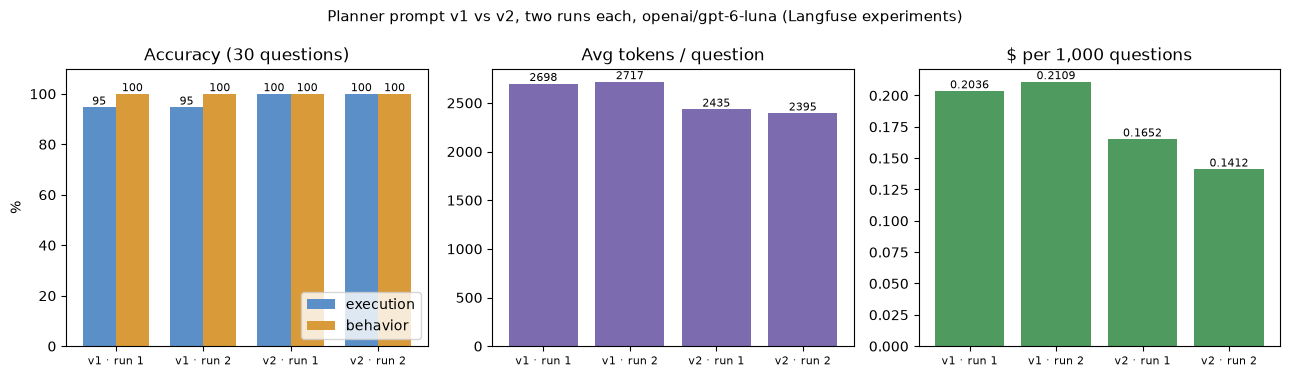

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
names = [k.replace("planner ", "") for k in summary.index]
x = list(range(len(summary)))
w = 0.38
axes[0].bar([i - w / 2 for i in x], summary["exec_acc_%"], w, label="execution", color="#5b8fc7")
axes[0].bar([i + w / 2 for i in x], summary["behavior_acc_%"], w, label="behavior",
            color="#d99a3a")
axes[0].set_ylim(0, 110); axes[0].set_ylabel("%"); axes[0].set_title("Accuracy (30 questions)")
axes[0].legend(loc="lower right")
axes[1].bar(x, summary["avg_tokens"], color="#7d6bb0"); axes[1].set_title("Avg tokens / question")
axes[2].bar(x, summary["usd_per_1k_q"], color="#4f9a5f")
axes[2].set_title("$ per 1,000 questions")
for ax, fmt in zip(axes, ("%.0f", "%.0f", "%.4f")):
    ax.set_xticks(x); ax.set_xticklabels(names, fontsize=8)
    for c in ax.containers:
        ax.bar_label(c, fmt=fmt, fontsize=8)
fig.suptitle(f"Planner prompt v1 vs v2, two runs each, {s.llm_model} (Langfuse experiments)",
             fontsize=11)
fig.tight_layout()
fig.savefig(IMAGES / "14-experiments.png", dpi=130, facecolor="white")
plt.show()

## 8. The dashboard, from code: Metrics API v2

In [17]:
def metrics(query: dict) -> pd.DataFrame:
    q = {"fromTimestamp": STARTED.isoformat(), "toTimestamp":
         (datetime.now(UTC) + timedelta(minutes=5)).isoformat()} | query
    return pd.DataFrame(lf.api.metrics.metrics(query=json.dumps(q)).data)

lf.flush(); time.sleep(5)
not_bench = [{"column": "environment", "operator": "=", "value": "default", "type": "string"}]
lat = metrics({"view": "observations", "dimensions": [{"field": "name"}], "filters": not_bench,
               "metrics": [{"measure": "count", "aggregation": "count"},
                           {"measure": "latency", "aggregation": "p50"},
                           {"measure": "latency", "aggregation": "p95"},
                           {"measure": "totalCost", "aggregation": "sum"}]})
print(lat.sort_values("p95_latency", ascending=False).round(4).to_string(index=False))

                  name  count_count  p50_latency  p95_latency  sum_totalCost
         sqlbot.answer            9       7407.0     12132.00         0.0000
                  plan            9       4682.0      7501.40         0.0014
                phrase            6       3738.5      5035.25         0.0005
chat openai/gpt-6-luna            1       3952.0      3952.00         0.0001
        postgres.query            6          7.0        20.50         0.0000
             sql_guard            6          3.0         4.00         0.0000


In [18]:
by_prompt = metrics({"view": "observations", "filters": not_bench + [
                         {"column": "type", "operator": "=", "value": "GENERATION",
                          "type": "string"}],
                     "dimensions": [{"field": "promptName"}, {"field": "promptVersion"}],
                     "metrics": [{"measure": "count", "aggregation": "count"},
                                 {"measure": "inputTokens", "aggregation": "avg"},
                                 {"measure": "totalCost", "aggregation": "sum"}]})
print(by_prompt.round(6).to_string(index=False))
feedback = metrics({"view": "scores-boolean", "dimensions": [{"field": "name"}],
                    "metrics": [{"measure": "count", "aggregation": "count"},
                                {"measure": "value", "aggregation": "avg"}]})
print(); print(feedback.to_string(index=False))

    promptName  promptVersion  count_count  avg_inputTokens  sum_totalCost
sqlbot-planner            1.0            9      2183.000000       0.001434
 sqlbot-answer            1.0            6       252.166667       0.000461
           NaN            NaN            1        15.000000       0.000076

         name  count_count  avg_value
user_feedback            2        0.5


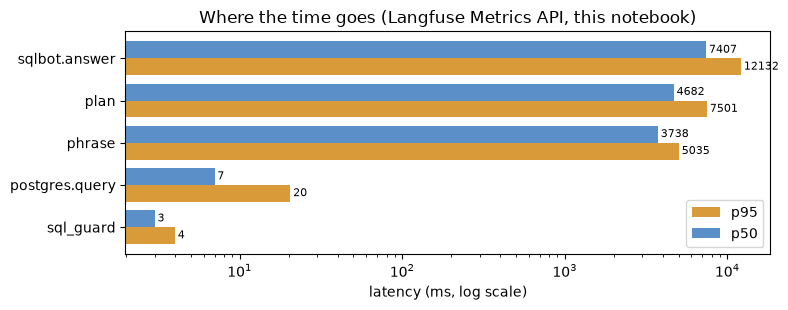

In [19]:
main = lat[lat["name"].isin(["sqlbot.answer", "plan", "phrase", "sql_guard", "postgres.query"])]
main = main.set_index("name").loc[["sqlbot.answer", "plan", "phrase", "postgres.query",
                                   "sql_guard"]]
fig, ax = plt.subplots(figsize=(8, 3.2))
y = range(len(main))
ax.barh([i + 0.2 for i in y], main["p95_latency"], 0.4, label="p95", color="#d99a3a")
ax.barh([i - 0.2 for i in y], main["p50_latency"], 0.4, label="p50", color="#5b8fc7")
ax.set_yticks(list(y)); ax.set_yticklabels(main.index); ax.invert_yaxis()
ax.set_xscale("log"); ax.set_xlabel("latency (ms, log scale)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8, padding=2)
ax.legend(loc="lower right"); ax.set_title("Where the time goes (Langfuse Metrics API, this notebook)")
fig.tight_layout(); fig.savefig(IMAGES / "14-latency-breakdown.png", dpi=130, facecolor="white")
plt.show()

## 9. Screenshots of the UI

saved ../images/14-trace.png
saved ../images/14-dashboard.png
saved ../images/14-experiments-ui.png



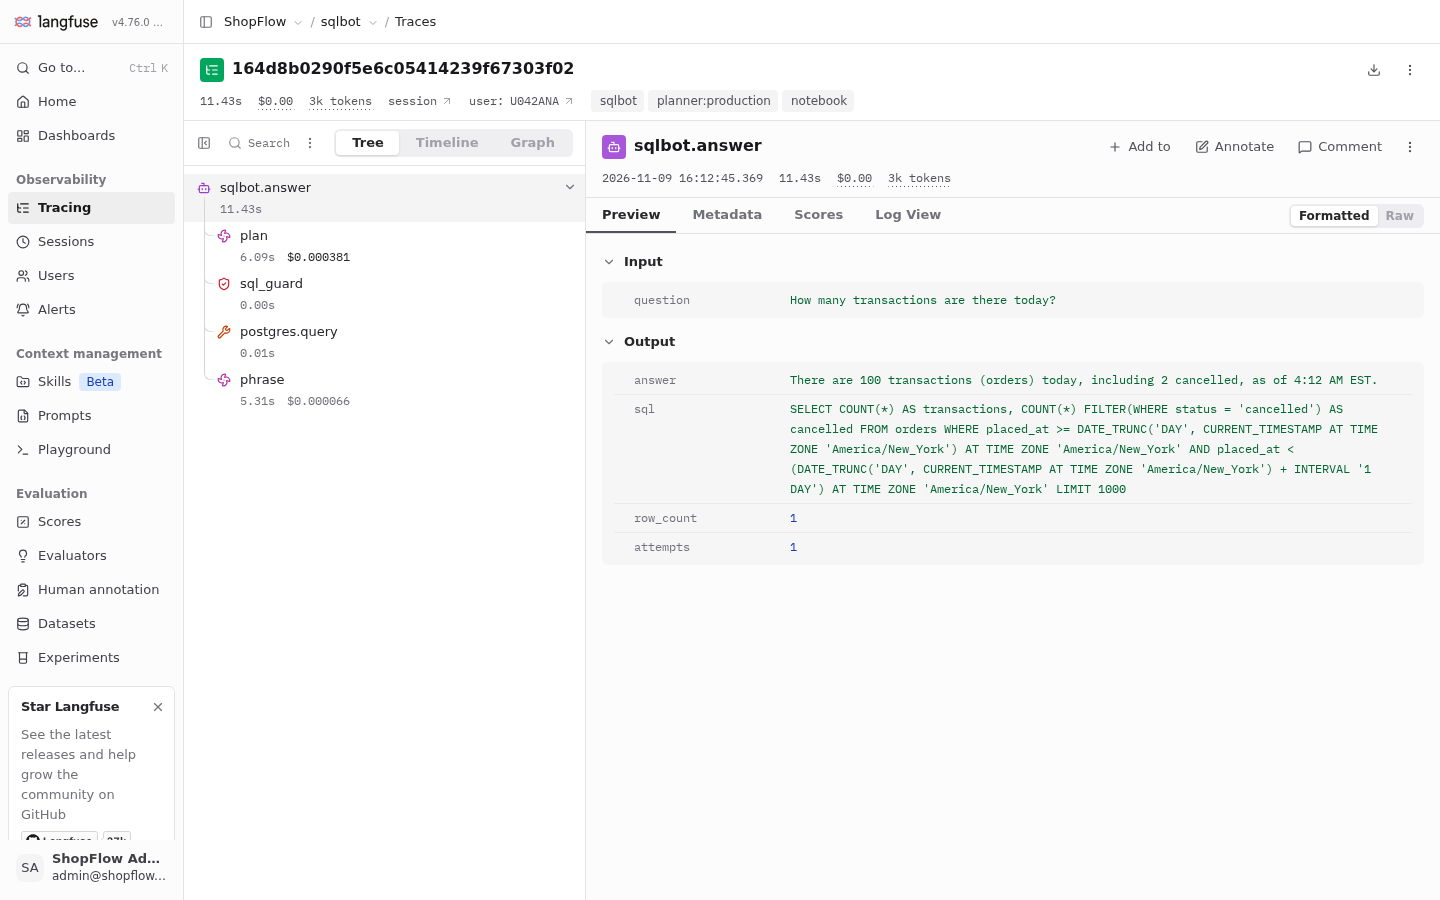

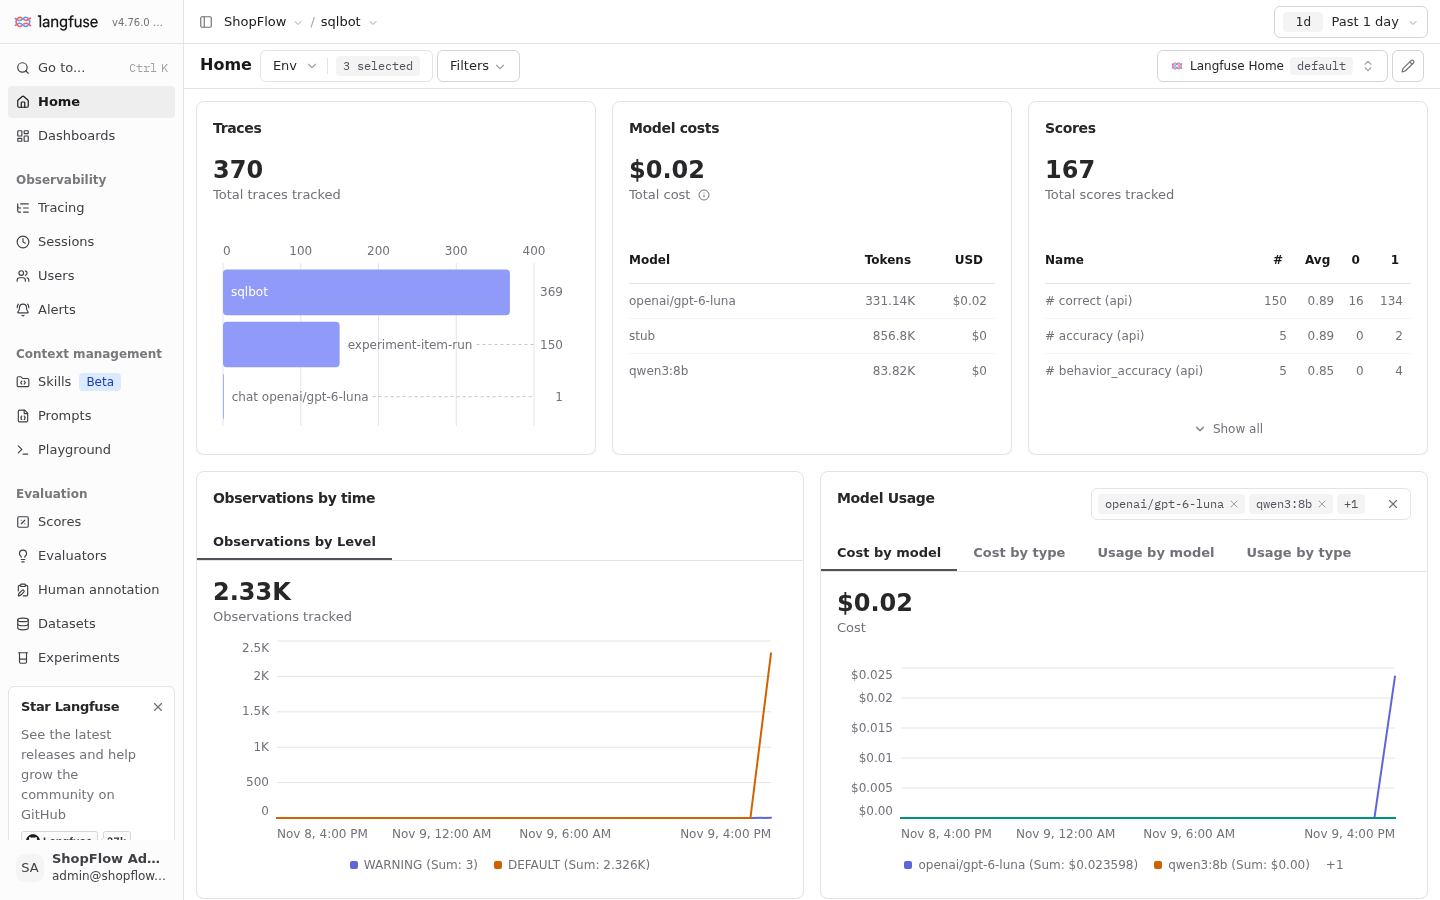

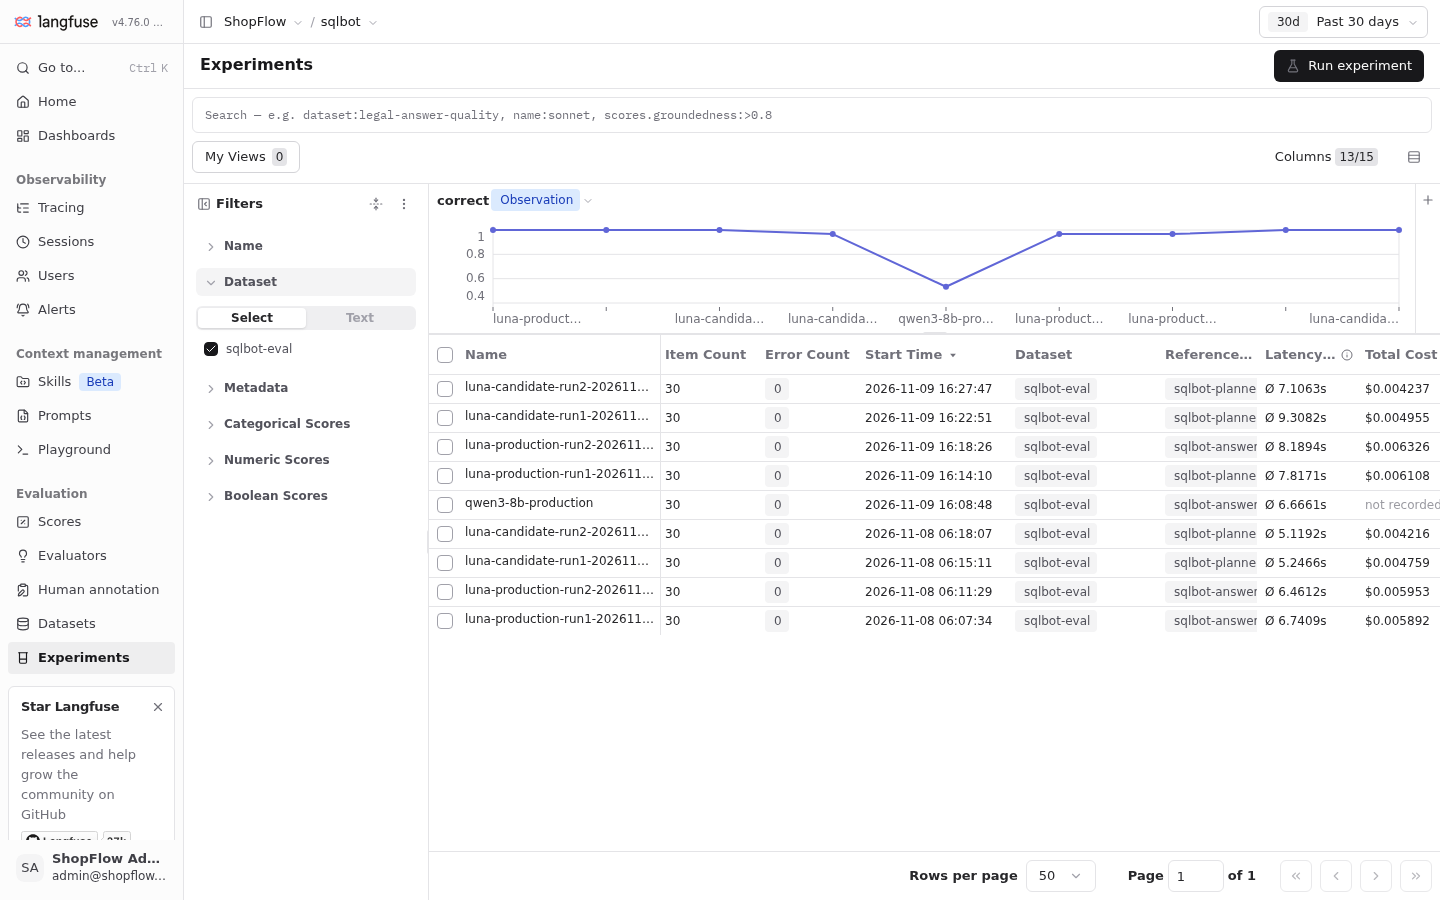

In [20]:
from IPython.display import Image, display

# Playwright's sync API can't run inside Jupyter's event loop: use the CLI in a subprocess.
base = obs.langfuse_settings()["base_url"]
shots = {f"/project/{obs.LOCAL_PROJECT_ID}/traces/{HEADLINE_TRACE}": IMAGES / "14-trace.png",
         f"/project/{obs.LOCAL_PROJECT_ID}": IMAGES / "14-dashboard.png",
         f"/project/{obs.LOCAL_PROJECT_ID}/experiments": IMAGES / "14-experiments-ui.png"}
print(subprocess.run([sys.executable, "ch14_screenshots.py"]
                     + [f"{path}={out}" for path, out in shots.items()],
                     capture_output=True, text=True, timeout=300, check=True).stdout)
for f in ("14-trace.png", "14-dashboard.png", "14-experiments-ui.png"):
    display(Image(filename=str(IMAGES / f), width=900))

## 10. What this notebook spent

In [21]:
lf.flush()
judge = items.judge_cost_usd.sum()
print(f"OpenRouter usage.cost summed over every call this notebook made: ${sum(SPEND):.4f}")
print(f"  of which judge calls ({(items.judge_cost_usd > 0).sum()} x {s.llm_model_strong}): "
      f"${judge:.4f}")
time.sleep(10)
delta = openrouter_key_usage() - KEY_USAGE_BEFORE
print(f"OpenRouter key usage delta during the run: ${delta:.4f} "
      "(shared key: includes other processes running at the same time)")

OpenRouter usage.cost summed over every call this notebook made: $0.1033
  of which judge calls (44 x anthropic/claude-sonnet-5.5): $0.0797


OpenRouter key usage delta during the run: $0.1029 (shared key: includes other processes running at the same time)
